Dataset Exploration and Preprocessing

The dataset contains three classes: donkey, horse, and zebra. I inspected the original images, verified their dimensions, and examined samples from each class before training.

The provided training directory was divided into training (80%) and validation (20%) subsets using stratification to preserve class proportions. The separate test directory was reserved for final evaluation.

Images were prepared using ResNet152V2's model-specific preprocessing, which scales pixel values to approximately -1 through 1.

I also demonstrated conservative augmentation techniques, including horizontal flipping, rotation, zoom, and brightness adjustment. These transformations were subsequently evaluated in a separate training experiment.

# 1.
**RUN PRIOR TO PRESENTATION**

DATASET / EVALUATION

Dataset setup and inventory

Mounts Google Drive, locates the Horse_Donkey_Zebra folders, and lists available images in the provided train and test directories.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

DATASET = Path("/content/drive/MyDrive/Horse_Donkey_Zebra")

for split in ["train", "test"]:
    print(f"\n{split.upper()}")

    split_path = DATASET / split

    for class_folder in sorted(split_path.iterdir()):
        if class_folder.is_dir():
            images = [
                f for f in class_folder.iterdir()
                if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
            ]

            print(f"{class_folder.name}: {len(images)}")

Mounted at /content/drive

TRAIN
donkey: 399
horse: 384
zebra: 226

TEST
donkey: 100
horse: 96
zebra: 60


#2.
 **RUN PRIOR TO PRESENTATION**

DATASET / EVALUATION

Verify image dimensions

Opens supported image files and checks their dimensions.

In [2]:
from PIL import Image

sizes = []

for path in DATASET.rglob("*"):
    if path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        with Image.open(path) as im:
            sizes.append(im.size)

print("Number of images:", len(sizes))
print("Unique image sizes:", set(sizes))

Number of images: 1265
Unique image sizes: {(224, 224)}


#3.
**RUN PRIOR TO PRESENTATION**

DATASET / EVALUATION

Inspect examples from each class

Displays sample donkey, horse, and zebra images from the original training folder.



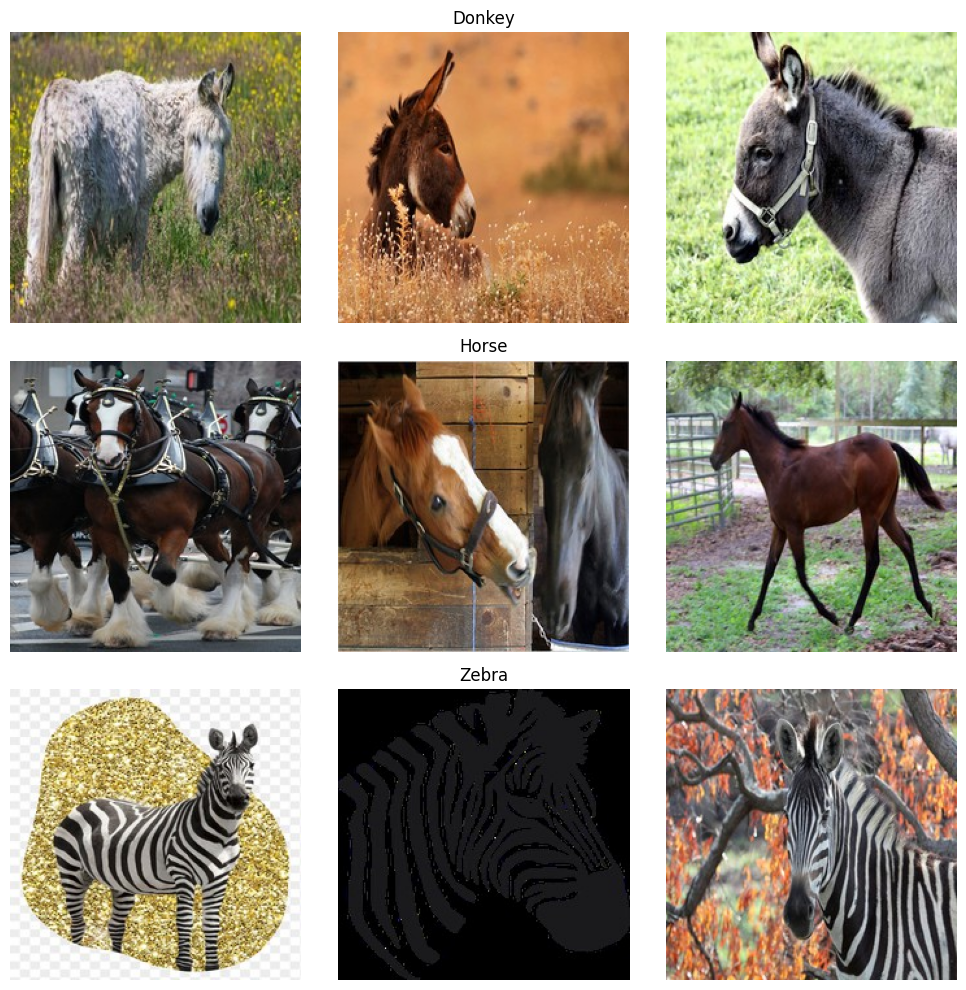

In [3]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import random
random.seed(42)

DATASET = Path("/content/drive/MyDrive/Horse_Donkey_Zebra")

classes = ["donkey", "horse", "zebra"]

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for row, class_name in enumerate(classes):
    class_folder = DATASET / "train" / class_name

    image_paths = [
        p for p in class_folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    selected = random.sample(image_paths, 3)

    for col, image_path in enumerate(selected):
        img = cv2.imread(str(image_path))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[row, col].imshow(img_rgb)
        axes[row, col].axis("off")

        if col == 1:
            axes[row, col].set_title(class_name.capitalize())

plt.tight_layout()
plt.show()

# 4.
**RUN PRIOR TO PRESENTATION**

DATASET / EVALUATION

Create stratified training and validation sets

Collects image paths and labels from the original training folder, then performs an 80/20 stratified split. The provided test directory remains separate.

In [4]:
from sklearn.model_selection import train_test_split

train_files = []
train_labels = []

for class_name in classes:
    class_folder = DATASET / "train" / class_name

    for image_path in class_folder.iterdir():
        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            train_files.append(str(image_path))
            train_labels.append(class_name)

X_train, X_val, y_train, y_val = train_test_split(
    train_files,
    train_labels,
    test_size=0.20,
    random_state=42,
    stratify=train_labels
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))

Training images: 807
Validation images: 202


# 5.
**RUN PRIOR TO PRESENTATION**

DATASET / EVALUATION

Count training and validation images

Prints per-class training and validation counts, so we can confirm that the split kept approximately the same animal proportions.

In [5]:
from collections import Counter

print("Training class counts:")
print(Counter(y_train))

print("\nValidation class counts:")
print(Counter(y_val))

Training class counts:
Counter({'donkey': 319, 'horse': 307, 'zebra': 181})

Validation class counts:
Counter({'donkey': 80, 'horse': 77, 'zebra': 45})


#6.
**OPTIONAL: RUN PRIOR TO PRESENTATION**

RESNET152V2

Demonstrate ResNet image preprocessing

Loads one training image and applies ResNet152V2 preprocessing. This changes numerical pixel values to the range expected by the pretrained model; it is not a separate training run.

Selected image:
/content/drive/MyDrive/Horse_Donkey_Zebra/train/donkey/donkey (431).jpg

Before preprocessing:
Min: 0 Max: 255

After ResNet152V2 preprocessing:
Min: -1.0 Max: 1.0


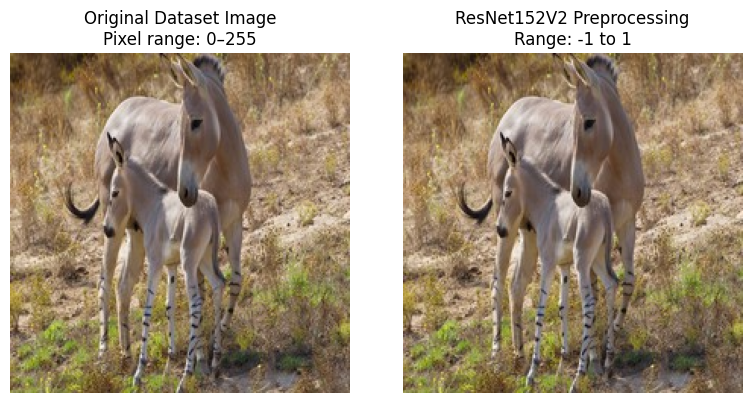

In [6]:
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.applications.resnet_v2 import preprocess_input

# Pick one random image from the TRAINING split
random.seed(42)

random_path = random.choice(X_train)

# Load image
img = cv2.imread(random_path)

# Convert BGR -> RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Images are already 224x224, so no resize is needed

# ResNet152V2 preprocessing
normalized = preprocess_input(img_rgb.astype(np.float32))

print("Selected image:")
print(random_path)

print("\nBefore preprocessing:")
print("Min:", img_rgb.min(), "Max:", img_rgb.max())

print("\nAfter ResNet152V2 preprocessing:")
print("Min:", normalized.min(), "Max:", normalized.max())

# Convert normalized image back to 0-1 ONLY for display
display_normalized = (normalized + 1.0) / 2.0

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(img_rgb)
axes[0].set_title("Original Dataset Image\nPixel range: 0–255")
axes[0].axis("off")

axes[1].imshow(display_normalized)
axes[1].set_title("ResNet152V2 Preprocessing\nRange: -1 to 1")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# 7.
**OPTIONAL: RUN PRIOR TO PRESENTATION**

DATASET / EVALUATION

Visualize proposed image augmentation

Demonstrates image flipping, rotation, and other changes on a training example. This visualization by itself does not augment the dataset used for the baseline model.

Selected image:
/content/drive/MyDrive/Horse_Donkey_Zebra/train/donkey/donkey (431).jpg


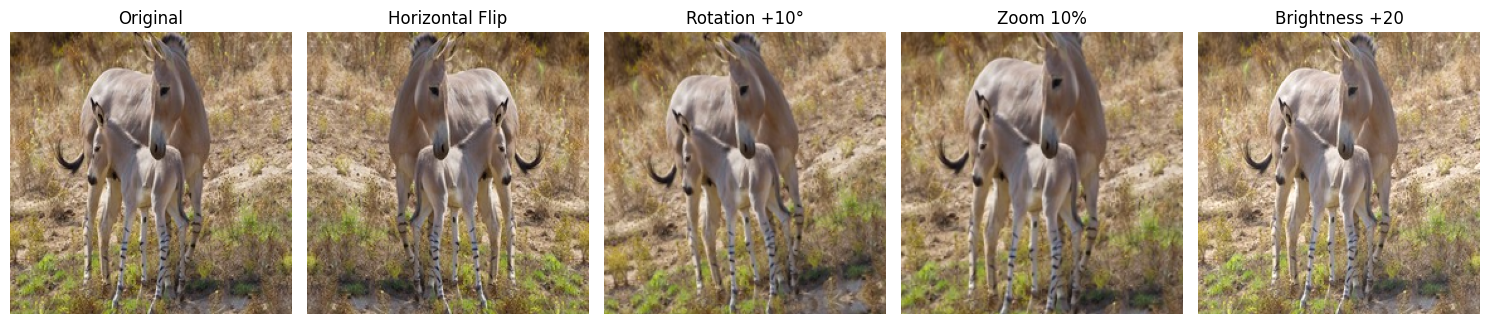

In [7]:
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the same reproducible random training image
random.seed(42)
random_path = random.choice(X_train)

# Load image
img = cv2.imread(random_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Selected image:")
print(random_path)

# 1. Horizontal flip
flipped = cv2.flip(img_rgb, 1)

# 2. Mild rotation: 10 degrees
h, w = img_rgb.shape[:2]
center = (w // 2, h // 2)

rotation_matrix = cv2.getRotationMatrix2D(
    center,
    10,      # degrees
    1.0      # scale
)

rotated = cv2.warpAffine(
    img_rgb,
    rotation_matrix,
    (w, h),
    borderMode=cv2.BORDER_REFLECT
)

# 3. Mild zoom: 10%
zoom_factor = 1.10

new_w = int(w * zoom_factor)
new_h = int(h * zoom_factor)

zoomed_large = cv2.resize(
    img_rgb,
    (new_w, new_h),
    interpolation=cv2.INTER_LINEAR
)

# Crop back to original 224x224 size
start_x = (new_w - w) // 2
start_y = (new_h - h) // 2

zoomed = zoomed_large[
    start_y:start_y + h,
    start_x:start_x + w
]

# 4. Mild brightness increase
brightness = cv2.convertScaleAbs(
    img_rgb,
    alpha=1.0,
    beta=20
)

# Display
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

images = [
    (img_rgb, "Original"),
    (flipped, "Horizontal Flip"),
    (rotated, "Rotation +10°"),
    (zoomed, "Zoom 10%"),
    (brightness, "Brightness +20")
]

for ax, (image, title) in zip(axes, images):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 8.
**RUN PRIOR TO PRESENTATION**

RESNET152V2

Build the TensorFlow image pipeline

Defines how to load image files, convert animal names to numeric labels, resize and preprocess images, and batch and prefetch training/validation data. The training set is shuffled; validation is not.

In [8]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

# Convert our class names into numerical labels
class_to_index = {name: i for i, name in enumerate(classes)}

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)

    # ResNet152V2 expects pixel values between -1 and 1
    image = tf.keras.applications.resnet_v2.preprocess_input(image)

    return image, label

def make_dataset(paths, labels, training=False):
    numerical_labels = [class_to_index[label] for label in labels]

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, numerical_labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)

print("Classes:", class_to_index)
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))

Classes: {'donkey': 0, 'horse': 1, 'zebra': 2}
Training batches: 51
Validation batches: 13


# 9.
**SHOW EXISTING OUTPUT — NO LIVE RUN REQUIRED**

RESNET152V2

Build frozen ResNet152V2 baseline

Loads pretrained ImageNet ResNet152V2 without its original classifier, freezes the backbone, and adds pooling, dropout, and a three-class softmax layer. Compiles using Adam and sparse categorical cross-entropy.

In [9]:
from tensorflow.keras.applications import ResNet152V2
from tensorflow.keras import layers, Model

# Load pretrained ResNet152V2 without its original classifier
base_model = ResNet152V2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers
base_model.trainable = False

# Build our classification model
inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    3,
    activation='softmax'
)(x)

model = Model(inputs, outputs)

# Configure training
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

234545216/234545216 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet152v2 (Functional)        │ (None, 7, 7, 2048)     │    58,331,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,337,795 (222.54 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 58,331,648 (222.52 MB)

# 10.
**DO NOT RERUN FOR PRESENTATION**

RESNET152V2

Train the frozen ResNet152V2 baseline

Train for early stopping

In [10]:

# Train frozen ResNet152V2 with early stopping

early_stopping_baseline = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    min_delta=0.001,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping_baseline]
)

print(f"Training completed after {len(history.history['loss'])} epochs.")


Epoch 1/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step - accuracy: 0.7670 - loss: 0.5615 - val_accuracy: 0.9257 - val_loss: 0.1880
Epoch 2/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 62s 133ms/step - accuracy: 0.9133 - loss: 0.2289 - val_accuracy: 0.9455 - val_loss: 0.1616
Epoch 3/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 139ms/step - accuracy: 0.9343 - loss: 0.1636 - val_accuracy: 0.9505 - val_loss: 0.1590
Epoch 4/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 129ms/step - accuracy: 0.9542 - loss: 0.1094 - val_accuracy: 0.9307 - val_loss: 0.1792
Epoch 5/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 143ms/step - accuracy: 0.9504 - loss: 0.1139 - val_accuracy: 0.9604 - val_loss: 0.1566
Epoch 6/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 135ms/step - accuracy: 0.9653 - loss: 0.0952 - val_accuracy: 0.9406 - val_loss: 0.1647
Epoch 7/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 11s 142ms/step - accuracy: 0.9628 - loss: 0.0937 - val_accuracy: 0.9455 - val_loss: 0.1612
Epoch 8/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 142ms/step - accuracy: 0.9740 - loss: 0.0798 - val_accuracy: 0

# 11.
**DO NOT RERUN FOR PRESENTATION**

RESNET152V2

Save the frozen ResNet model

Creates the project output directory and saves the trained baseline model to Google Drive as a .keras file, so its learned weights can be restored later.


In [11]:
from google.colab import drive
import os

# Connect Google Drive (if not already mounted)
drive.mount('/content/drive')

# Create a folder for our project
save_dir = '/content/drive/MyDrive/DHZ_Final_Project'
os.makedirs(save_dir, exist_ok=True)

# Save the trained model
model.save(f'{save_dir}/resnet152v2_baseline.keras')

print("Model saved successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved successfully!


# 12.
**SHOW EXISTING OUTPUT — NO LIVE RUN REQUIRED**

RESNET152V2

Save baseline training history and plot accuracy

Converts epoch-by-epoch training metrics into a table, saves them as CSV, and creates a plot comparing training accuracy with validation accuracy.

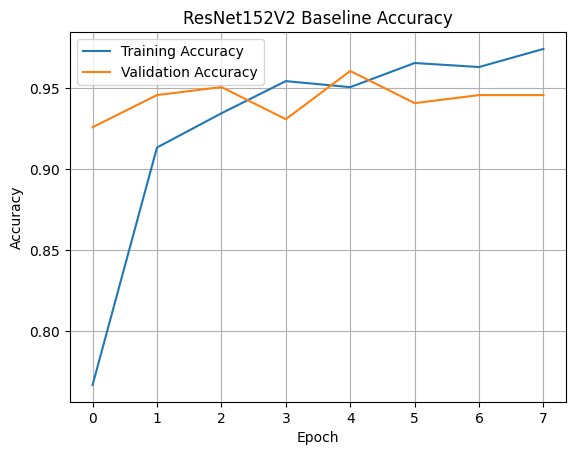

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Turn training results into a table
results = pd.DataFrame(history.history)

# Save results to Google Drive
results.to_csv(
    f'{save_dir}/baseline_training_history.csv',
    index=False
)

# Plot accuracy
plt.plot(results['accuracy'], label='Training Accuracy')
plt.plot(results['val_accuracy'], label='Validation Accuracy')

plt.title('ResNet152V2 Baseline Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.savefig(
    f'{save_dir}/baseline_accuracy.png',
    bbox_inches='tight'
)
plt.show()

# 13.
**SHOW EXISTING OUTPUT — NO LIVE RUN REQUIRED**

RESNET152V2

Plot baseline training and validation loss

Displays and saves the loss curves for the frozen ResNet baseline. These help evaluate learning behavior and potential overfitting.

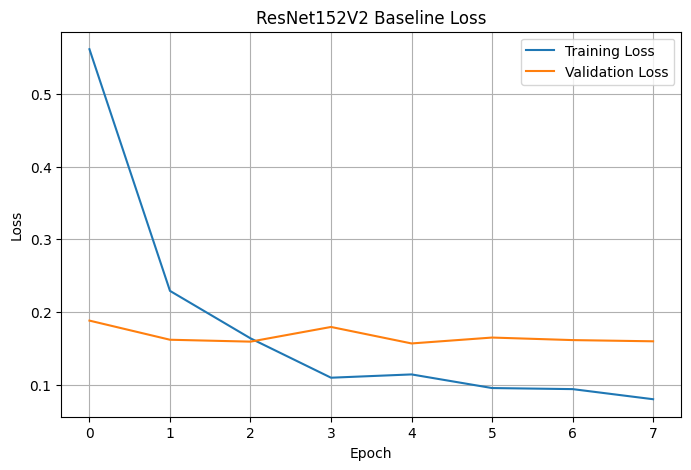

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(results['loss'], label='Training Loss')
plt.plot(results['val_loss'], label='Validation Loss')

plt.title('ResNet152V2 Baseline Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.savefig(
    f'{save_dir}/baseline_loss.png',
    bbox_inches='tight'
)

plt.show()

# 14.
**SHOW EXISTING OUTPUT — NO LIVE RUN REQUIRED**

RESNET152V2

Summarize baseline validation results - early stopping


Reports the best validation epoch, best validation accuracy, and final training/validation metrics. Our recorded best ResNet validation accuracy was 96.04%.

In [14]:

# Summarize early-stopping baseline experiment

best_epoch = results['val_loss'].idxmin()

print("BASELINE RESULTS")
print("----------------------------")
print(f"Epochs completed: {len(results)}")
print(f"Best epoch by validation loss: {best_epoch + 1}")
print(f"Best validation accuracy: {results['val_accuracy'].max():.2%}")
print(f"Best validation loss: {results['val_loss'].min():.4f}")
print(f"Final recorded training accuracy: {results['accuracy'].iloc[-1]:.2%}")
print(f"Final recorded validation accuracy: {results['val_accuracy'].iloc[-1]:.2%}")


BASELINE RESULTS
----------------------------
Epochs completed: 8
Best epoch by validation loss: 5
Best validation accuracy: 96.04%
Best validation loss: 0.1566
Final recorded training accuracy: 97.40%
Final recorded validation accuracy: 94.55%


# 15.
**SHOW EXISTING OUTPUT — NO LIVE RUN REQUIRED**

RESNET152V2

Configure partial ResNet fine-tuning

Loads a separate copy of the saved baseline, unfreezes the final 20 backbone layers, keeps batch-normalization layers frozen, and recompiles with a smaller learning rate.

In [15]:
# Load a copy so we preserve our original baseline

fine_tune_model = tf.keras.models.load_model(
    f'{save_dir}/resnet152v2_baseline.keras'
)

# Access the pretrained ResNet backbone
base = fine_tune_model.get_layer('resnet152v2')

# Allow selected layers to be trained
base.trainable = True

# Freeze everything except the last 20 layers
for layer in base.layers[:-20]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a much smaller learning rate
fine_tune_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Trainable parameters:",
      sum(int(tf.size(w)) for w in fine_tune_model.trainable_weights))

Trainable parameters: 7874563


# 16.
**DO NOT RERUN FOR PRESENTATION**

RESNET152V2

Train and checkpoint fine-tuned ResNet

Fine-tunes for up to three epochs, saving the checkpoint with the lowest validation loss and using early stopping. Do not rerun in the live presentation.

In [16]:

# Save the best fine-tuned model automatically
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=f'{save_dir}/resnet152v2_finetuned.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose=1
)

# Stop when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    min_delta=0.001,
    restore_best_weights=True,
    verbose=1
)

# Fine-tune with early stopping
fine_tune_history = fine_tune_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[checkpoint, early_stopping]
)


Epoch 1/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step - accuracy: 0.9706 - loss: 0.0975
Epoch 1: val_loss improved from None to 0.18482, saving model to /content/drive/MyDrive/DHZ_Final_Project/resnet152v2_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DHZ_Final_Project/resnet152v2_finetuned.keras
51/51 ━━━━━━━━━━━━━━━━━━━━ 72s 829ms/step - accuracy: 0.9653 - loss: 0.0895 - val_accuracy: 0.9307 - val_loss: 0.1848
Epoch 2/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.9898 - loss: 0.0382
Epoch 2: val_loss improved from 0.18482 to 0.15699, saving model to /content/drive/MyDrive/DHZ_Final_Project/resnet152v2_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DHZ_Final_Project/resnet152v2_finetuned.keras
51/51 ━━━━━━━━━━━━━━━━━━━━ 19s 384ms/step - accuracy: 0.9876 - loss: 0.0413 - val_accuracy: 0.9505 - val_loss: 0.1570
Epoch 3/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.9954 - loss: 0.0253
Epoch 3: val_loss did not i

# 17.
**SHOW EXISTING OUTPUT — NO LIVE RUN REQUIRED**

RESNET152V2

Compare ResNet baseline and fine-tuned results

Compares best validation accuracy and minimum validation loss across the original frozen model and partial fine-tuning. Fine-tuning did not improve best validation accuracy.

In [18]:
import pandas as pd

fine_results = pd.DataFrame(fine_tune_history.history)

print("BASELINE")
print(f"Best validation accuracy: {results['val_accuracy'].max():.2%}")
print(f"Best validation loss: {results['val_loss'].min():.4f}")

print("\nFINE-TUNED")
print(f"Best validation accuracy: {fine_results['val_accuracy'].max():.2%}")
print(f"Best validation loss: {fine_results['val_loss'].min():.4f}")

BASELINE
Best validation accuracy: 96.04%
Best validation loss: 0.1566

FINE-TUNED
Best validation accuracy: 95.05%
Best validation loss: 0.1570


# 18.
**SHOW EXISTING OUTPUT — NO LIVE RUN REQUIRED**

RESNET152V2

Save ResNet fine-tuning comparison

Builds and saves a table recording validation metrics and trainable-parameter counts for the frozen and fine-tuned ResNet experiments.

In [19]:
comparison = pd.DataFrame({
    'Model': ['Frozen Baseline', 'Fine-Tuned'],
    'Best Validation Accuracy': [
        results['val_accuracy'].max(),
        fine_results['val_accuracy'].max()
    ],
    'Best Validation Loss': [
        results['val_loss'].min(),
        fine_results['val_loss'].min()
    ],
    'Trainable Parameters': [6147, 7874563]
})

display(comparison)

comparison.to_csv(
    f'{save_dir}/model_comparison.csv',
    index=False
)

,Model,Best Validation Accuracy,Best Validation Loss,Trainable Parameters
0,Frozen Baseline,0.960396,0.156555,6147
1,Fine-Tuned,0.950495,0.156994,7874563


# 19.
**RUN PRIOR TO PRESENTATION**

DATASET / EVALUATION

Prepare the original held-out test set

Reads paths and labels from the separate test folder and constructs a test dataset without training-time augmentation or shuffling.

In [20]:
import os

# Location of our untouched test images
test_dir = '/content/drive/MyDrive/Horse_Donkey_Zebra/test'

# Collect image paths and corresponding labels
X_test = []
y_test = []

for class_name in classes:
    class_folder = os.path.join(test_dir, class_name)

    for filename in sorted(os.listdir(class_folder)):
        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            X_test.append(os.path.join(class_folder, filename))
            y_test.append(class_name)

# Reuse our existing image-loading function
test_ds = make_dataset(X_test, y_test, training=False)

print("Total test images:", len(X_test))
print("Test batches:", len(test_ds))
print("Test class distribution:")

for class_name in classes:
    print(f"{class_name}: {y_test.count(class_name)}")

Total test images: 256
Test batches: 16
Test class distribution:
donkey: 100
horse: 96
zebra: 60


# 20.
**SHOW EXISTING OUTPUT — NO LIVE RUN REQUIRED**

RESNET152V2

Evaluate selected ResNet on original test set

Restores the frozen ResNet baseline and evaluates it on the originally supplied 256-image test set. This is the pre-audit result (92.97%), not the corrected result.

In [21]:
# Load the saved frozen baseline
final_model = tf.keras.models.load_model(
    f'{save_dir}/resnet152v2_baseline.keras'
)

# Evaluate on the held-out test dataset
test_loss, test_accuracy = final_model.evaluate(test_ds)

print("\nFINAL TEST RESULTS")
print("----------------------------")
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test loss: {test_loss:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - accuracy: 0.9297 - loss: 0.1896

FINAL TEST RESULTS
----------------------------
Test accuracy: 92.97%
Test loss: 0.1896


# 21.
**SHOW EXISTING OUTPUT — NO LIVE RUN REQUIRED**

RESNET152V2

Classification report and original confusion matrix

Produces predictions on the original 256-image test set, calculates precision/recall/F1, and saves a confusion matrix. It predates duplicate removal and must be labeled accordingly.

16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step
CLASSIFICATION REPORT
              precision    recall  f1-score   support

      donkey     0.9468    0.8900    0.9175       100
       horse     0.8750    0.9479    0.9100        96
       zebra     1.0000    0.9667    0.9831        60

    accuracy                         0.9297       256
   macro avg     0.9406    0.9349    0.9369       256
weighted avg     0.9323    0.9297    0.9301       256



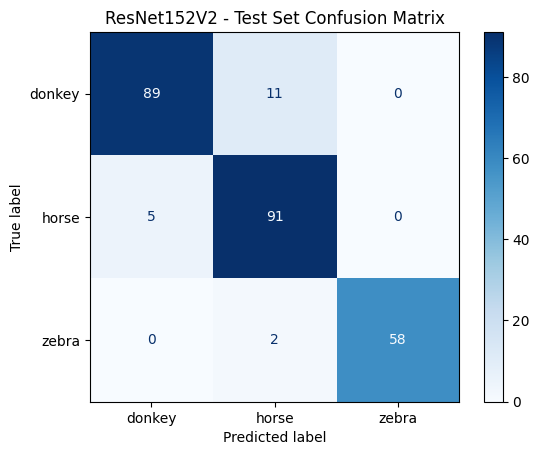

In [22]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get the model's predictions for each test image
predictions = final_model.predict(test_ds)

# Convert probabilities into predicted class numbers
y_pred = np.argmax(predictions, axis=1)

# Convert actual animal names into numerical labels
y_true = np.array([class_to_index[label] for label in y_test])

# Print precision, recall, and F1 scores
print("CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=classes,
    digits=4
))

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(cmap='Blues', values_format='d')
plt.title('ResNet152V2 - Test Set Confusion Matrix')
plt.savefig(
    f'{save_dir}/test_confusion_matrix.png',
    bbox_inches='tight',
    dpi=150
)
plt.show()

# 22.
**SHOW EXISTING OUTPUT — NO LIVE RUN REQUIRED**

RESNET152V2

Export original classification metrics

Saves the original test-set classification report in CSV format for the project record and presentation.

In [23]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    y_true,
    y_pred,
    target_names=classes,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    f'{save_dir}/test_classification_report.csv'
)

display(report_df)

,precision,recall,f1-score,support
donkey,0.946809,0.890000,0.917526,100.000000
horse,0.875000,0.947917,0.910000,96.000000
zebra,1.000000,0.966667,0.983051,60.000000
accuracy,0.929688,0.929688,0.929688,0.929688
macro avg,0.940603,0.934861,0.936859,256.000000
weighted avg,0.932347,0.929688,0.930061,256.000000


# 23.
**RUN PRIOR TO PRESENTATION**

DATASET / EVALUATION

Audit class counts and exact train/test duplicates

Lists per-class counts for training, validation and test, then checks exact file duplicates between the combined training/validation collection and the provided test directory using SHA-256 hashes.

In [24]:
from collections import Counter
import hashlib

# Count each animal in our three splits
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}:")
    for animal, count in sorted(Counter(labels).items()):
        print(f"  {animal}: {count}")

# Check for exact duplicates across the original train/test split
def file_hash(path):
    sha = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            sha.update(chunk)
    return sha.hexdigest()

train_hashes = {
    file_hash(path) for path in list(X_train) + list(X_val)
}

duplicate_paths = [
    path for path in X_test
    if file_hash(path) in train_hashes
]

print("\nExact train/test duplicate files:", len(duplicate_paths))


Training:
  donkey: 319
  horse: 307
  zebra: 181

Validation:
  donkey: 80
  horse: 77
  zebra: 45

Test:
  donkey: 100
  horse: 96
  zebra: 60

Exact train/test duplicate files: 1


# 24.
**RUN PRIOR TO PRESENTATION**

DATASET / EVALUATION

Show duplicate-image evidence

Finds the matching original and test filenames, identifies whether the original appeared in training or validation, and displays the verified identical images side by side.

DUPLICATE IMAGE FOUND
----------------------------
Original: /content/drive/MyDrive/Horse_Donkey_Zebra/train/donkey/donkey (240).jpg
Test: /content/drive/MyDrive/Horse_Donkey_Zebra/test/donkey/donkey (14).jpg
Original split: Training


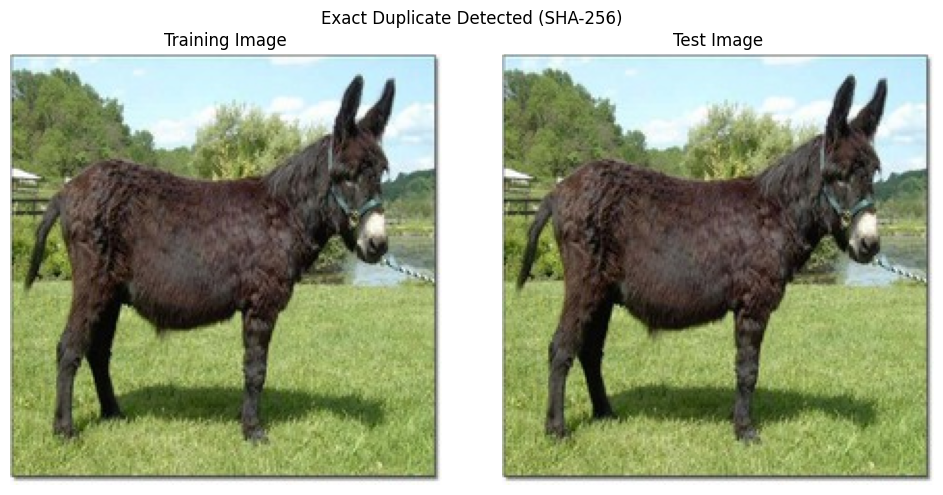

In [25]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Combine training and validation image paths
all_train_paths = list(X_train) + list(X_val)

# Match file hashes to their original images
hash_to_train = {}

for path in all_train_paths:
    h = file_hash(path)
    hash_to_train.setdefault(h, []).append(path)

# Display each duplicate pair
for test_path in duplicate_paths:

    matching_paths = hash_to_train[file_hash(test_path)]

    for match_path in matching_paths:

        split = "Training" if match_path in X_train else "Validation"

        print("DUPLICATE IMAGE FOUND")
        print("----------------------------")
        print("Original:", match_path)
        print("Test:", test_path)
        print("Original split:", split)

        # Open both images
        original_img = Image.open(match_path)
        test_img = Image.open(test_path)

        # Display side by side
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        axes[0].imshow(original_img)
        axes[0].set_title(f"{split} Image")
        axes[0].axis('off')

        axes[1].imshow(test_img)
        axes[1].set_title("Test Image")
        axes[1].axis('off')

        plt.suptitle("Exact Duplicate Detected (SHA-256)")
        plt.tight_layout()

        # Save figure for our presentation
        plt.savefig(
            f'{save_dir}/duplicate_comparison.png',
            dpi=150,
            bbox_inches='tight'
        )

        plt.show()

# 25.
**RUN PRIOR TO PRESENTATION**

RESNET152V2

Correct the test evaluation after duplicate removal

Creates a corrected test dataset that excludes the identified duplicate and evaluates the already-selected frozen ResNet. The corrected result was 92.94% over 255 images.

In [26]:
# Remove duplicate images from the test dataset
clean_test_paths = [
    path for path in X_test
    if path not in duplicate_paths
]

clean_test_labels = [
    label for path, label in zip(X_test, y_test)
    if path not in duplicate_paths
]

# Build corrected test dataset
clean_test_ds = make_dataset(
    clean_test_paths,
    clean_test_labels,
    training=False
)

# Evaluate our existing model without retraining
clean_loss, clean_accuracy = final_model.evaluate(clean_test_ds)

print("\nCORRECTED TEST RESULTS")
print("----------------------------")
print(f"Original test images: {len(X_test)}")
print(f"Corrected test images: {len(clean_test_paths)}")
print(f"Corrected test accuracy: {clean_accuracy:.2%}")
print(f"Corrected test loss: {clean_loss:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.9294 - loss: 0.1904

CORRECTED TEST RESULTS
----------------------------
Original test images: 256
Corrected test images: 255
Corrected test accuracy: 92.94%
Corrected test loss: 0.1904


# 26.
**OPTIONAL: RUN PRIOR TO PRESENTATION**
MOBILENETV2
Build the MobileNetV2 input pipeline

Defines MobileNetV2-specific image preprocessing and makes training/validation datasets using the same image splits as ResNet. This supports a fair architecture comparison.

In [27]:
# MobileNetV2 preprocessing
def load_mobilenet_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (224, 224))

    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label


def make_mobilenet_dataset(paths, labels, training=False):
    numerical_labels = [class_to_index[label] for label in labels]

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, numerical_labels)
    )

    if training:
        dataset = dataset.shuffle(len(paths), seed=42)

    dataset = dataset.map(
        load_mobilenet_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(16).prefetch(tf.data.AUTOTUNE)


mobile_train_ds = make_mobilenet_dataset(
    X_train, y_train, training=True
)

mobile_val_ds = make_mobilenet_dataset(
    X_val, y_val
)

print("MobileNet training batches:", len(mobile_train_ds))
print("MobileNet validation batches:", len(mobile_val_ds))

MobileNet training batches: 51
MobileNet validation batches: 13


# 27.
**SHOW EXISTING OUTPUT — NO LIVE RUN REQUIRED**
MOBILENETV2
Build frozen MobileNetV2 classifier

Loads pretrained MobileNetV2, freezes its backbone, and adds a three-class classification head with matching optimizer, learning rate, and loss settings.

In [28]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, Model

# Load pretrained MobileNetV2
mobile_base = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers
mobile_base.trainable = False

# Build our three-class classifier
inputs = layers.Input(shape=(224, 224, 3))

x = mobile_base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    3,
    activation='softmax'
)(x)

mobile_model = Model(inputs, outputs)

# Use the same training configuration as our ResNet baseline
mobile_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

mobile_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# 28.
**DO NOT RERUN FOR PRESENTATION**

MOBILENETV2

Train MobileNetV2 baseline

Trains the frozen MobileNetV2 classifier using early stopping, allowing up to 20 epochs while monitoring validation loss. Training stops after three consecutive epochs without sufficient improvement, restoring the best model weights. Training duration is recorded for comparison with ResNet152V2.


In [29]:

import time

# Early stopping for MobileNetV2
early_stopping_mobile = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    min_delta=0.001,
    restore_best_weights=True,
    verbose=1
)

# Measure how long MobileNetV2 takes to train
start_time = time.perf_counter()

# Train MobileNetV2 with early stopping
mobile_history = mobile_model.fit(
    mobile_train_ds,
    validation_data=mobile_val_ds,
    epochs=20,
    callbacks=[early_stopping_mobile]
)

mobile_training_time = time.perf_counter() - start_time

print(f"\nMobileNetV2 training time: {mobile_training_time:.1f} seconds")
print(f"Epochs completed: {len(mobile_history.history['loss'])}")


Epoch 1/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 59s 721ms/step - accuracy: 0.7187 - loss: 0.6168 - val_accuracy: 0.8713 - val_loss: 0.3285
Epoch 2/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.9120 - loss: 0.2505 - val_accuracy: 0.9455 - val_loss: 0.1973
Epoch 3/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9393 - loss: 0.1807 - val_accuracy: 0.9406 - val_loss: 0.1764
Epoch 4/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.9566 - loss: 0.1433 - val_accuracy: 0.9505 - val_loss: 0.1690
Epoch 5/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.9628 - loss: 0.1239 - val_accuracy: 0.9505 - val_loss: 0.1616
Epoch 6/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9703 - loss: 0.1046 - val_accuracy: 0.9455 - val_loss: 0.1564
Epoch 7/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.9703 - loss: 0.0987 - val_accuracy: 0.9455 - val_loss: 0.1566
Epoch 8/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9690 - loss: 0.0921 - val_accuracy: 0.9455 -

# 29.
**DO NOT RERUN FOR PRESENTATION**

MOBILENETV2

Save MobileNetV2 and compare validation accuracy

Saves the MobileNet model and training history to Drive, and prints its validation result beside the ResNet baseline. Best MobileNet validation accuracy was 95.05%.

In [30]:
# Save our MobileNetV2 model
mobile_model.save(
    f'{save_dir}/mobilenetv2_baseline.keras'
)

# Save training history
mobile_results = pd.DataFrame(mobile_history.history)

mobile_results.to_csv(
    f'{save_dir}/mobilenetv2_training_history.csv',
    index=False
)

# Compare validation performance
print("\nMODEL COMPARISON")
print("----------------------------")

print(
    f"ResNet152V2 best validation accuracy: "
    f"{results['val_accuracy'].max():.2%}"
)

print(
    f"MobileNetV2 best validation accuracy: "
    f"{mobile_results['val_accuracy'].max():.2%}"
)

print(
    f"MobileNetV2 training time: "
    f"{mobile_training_time:.1f} seconds"
)


MODEL COMPARISON
----------------------------
ResNet152V2 best validation accuracy: 96.04%
MobileNetV2 best validation accuracy: 95.54%
MobileNetV2 training time: 85.2 seconds


# 30.
**SHOW EXISTING OUTPUT — NO LIVE RUN REQUIRED**

RESNET152V2 + MOBILENETV2

Plot architecture comparison

Plots ResNet152V2 and MobileNetV2 validation accuracy across epochs, providing evidence for the comparison of model complexity and accuracy.

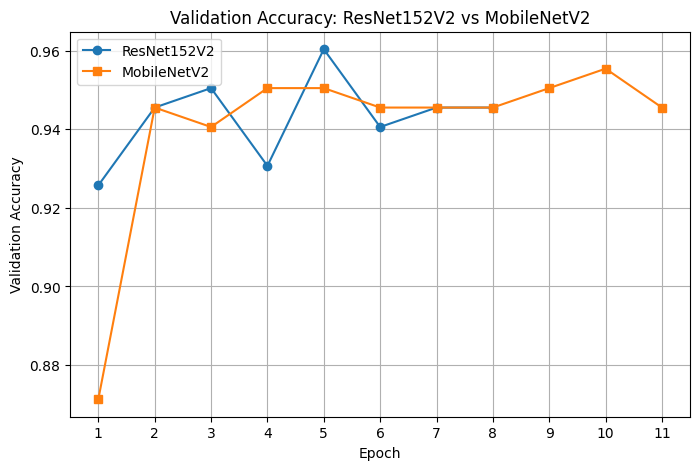

In [37]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(results) + 1),
    results['val_accuracy'],
    marker='o',
    label='ResNet152V2'
)

plt.plot(
    range(1, len(mobile_results) + 1),
    mobile_results['val_accuracy'],
    marker='s',
    label='MobileNetV2'
)

plt.title('Validation Accuracy: ResNet152V2 vs MobileNetV2')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.xticks(range(1, max(len(results), len(mobile_results)) + 1))
plt.legend()
plt.grid(True)

plt.savefig(
    f'{save_dir}/architecture_comparison.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()




# 31.
**RUN PRIOR TO PRESENTATION**

RESNET152V2 + MOBILENETV2

Restore saved models and experiment histories

Loads previously saved ResNet/MobileNet models and their CSV histories from Google Drive. This is the main shortcut for presenting results without retraining.

In [32]:
import os
import pandas as pd
import tensorflow as tf

save_dir = '/content/drive/MyDrive/DHZ_Final_Project'

# Restore our training histories
results = pd.read_csv(
    f'{save_dir}/baseline_training_history.csv'
)

mobile_results = pd.read_csv(
    f'{save_dir}/mobilenetv2_training_history.csv'
)

# Restore our trained models
final_model = tf.keras.models.load_model(
    f'{save_dir}/resnet152v2_baseline.keras'
)

mobile_model = tf.keras.models.load_model(
    f'{save_dir}/mobilenetv2_baseline.keras'
)

print("Models and training histories restored!")
print("ResNet validation accuracy:",
      f"{results['val_accuracy'].max():.2%}")
print("MobileNet validation accuracy:",
      f"{mobile_results['val_accuracy'].max():.2%}")

Models and training histories restored!
ResNet validation accuracy: 96.04%
MobileNet validation accuracy: 95.54%


# 32.
**RUN PRIOR TO PRESENTATION**

RESNET152V2

Rebuild training and validation dataset objects

Reconstructs TensorFlow datasets in a fresh Colab session without training a model. Required for the augmentation pipeline that follows.

In [33]:
# Rebuild datasets without retraining the model
train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))

Training batches: 51
Validation batches: 13


# 33.
**RUN PRIOR TO PRESENTATION**

RESNET152V2

Apply augmentation to training images only

Defines random horizontal flip, rotation, zoom, and brightness changes, and applies them only to the training dataset. Validation images remain unaugmented.

In [34]:
from tensorflow.keras import layers

# Augmentation layers for our training images
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1, value_range=(-1, 1))
], name="training_augmentation")

# Apply augmentation only to training data
def augment_image(image, label):
    image = augmentation(image, training=True)
    return image, label

augmented_train_ds = train_ds.map(
    augment_image,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

print("Augmented training batches:", len(augmented_train_ds))
print("Validation batches:", len(val_ds))


Augmented training batches: 51
Validation batches: 13


# 34.
**DO NOT RERUN FOR PRESENTATION**

RESNET152V2

Train fresh ResNet with augmentation

Builds a newly initialized classification head on a frozen ResNet152V2 backbone and trains for five epochs on augmented images to compare against the original frozen baseline.

In [35]:
from tensorflow.keras.applications import ResNet152V2
from tensorflow.keras import layers, Model
import time

# Build a fresh ResNet152V2
aug_base = ResNet152V2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
aug_base.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = aug_base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(3, activation='softmax')(x)

aug_model = Model(inputs, outputs)

aug_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train with augmentation
start_time = time.perf_counter()

aug_history = aug_model.fit(
    augmented_train_ds,
    validation_data=val_ds,
    epochs=5
)

aug_training_time = time.perf_counter() - start_time

print(f"\nAugmented training time: {aug_training_time:.1f} seconds")

Epoch 1/5
51/51 ━━━━━━━━━━━━━━━━━━━━ 70s 876ms/step - accuracy: 0.8017 - loss: 0.4762 - val_accuracy: 0.9257 - val_loss: 0.2033
Epoch 2/5
51/51 ━━━━━━━━━━━━━━━━━━━━ 12s 231ms/step - accuracy: 0.8996 - loss: 0.2696 - val_accuracy: 0.9257 - val_loss: 0.1874
Epoch 3/5
51/51 ━━━━━━━━━━━━━━━━━━━━ 12s 239ms/step - accuracy: 0.9133 - loss: 0.2196 - val_accuracy: 0.9505 - val_loss: 0.1845
Epoch 4/5
51/51 ━━━━━━━━━━━━━━━━━━━━ 12s 221ms/step - accuracy: 0.9257 - loss: 0.1804 - val_accuracy: 0.9059 - val_loss: 0.2027
Epoch 5/5
51/51 ━━━━━━━━━━━━━━━━━━━━ 10s 195ms/step - accuracy: 0.9318 - loss: 0.1745 - val_accuracy: 0.9356 - val_loss: 0.1910

Augmented training time: 116.7 seconds


# 35.
**DO NOT RERUN FOR PRESENTATION**

RESNET152V2

Save augmentation experiment results

Saves the final-epoch augmented model and CSV history. Its highest validation accuracy during the run was 92.08%, though the saved final-epoch weights are not necessarily the peak-accuracy checkpoint.


In [38]:
aug_model.save(
    f'{save_dir}/resnet152v2_augmented.keras'
)

aug_results = pd.DataFrame(aug_history.history)

aug_results.to_csv(
    f'{save_dir}/augmented_training_history.csv',
    index=False
)

print("Augmented model and history saved!")
print(f"Best validation accuracy: {aug_results['val_accuracy'].max():.2%}")

Augmented model and history saved!
Best validation accuracy: 95.05%
